# 10.18 — 3D GP + GRG closed-loop test results

This is Johnson Ji 10.18 test, focus on the python integration and implementation of 3D GP + GRG, which is in order to achieve the closed loop navigation and temperature measurement, rebuild and prediction.

Objective: validate historical GP initialization, time-aware GRG, simulated navigation,
online conditioning, and fixed-time reconstruction. All temperatures are synthetic.
[Method and rubric](README.md) · [Code audit](10.18_result/baseline/code_audit.md).


## Given conditions and assumptions

The environment, temperature source, historical dataset, and candidate set are given before the mission. The robot selects sampling destinations; it does not discover the map or generate the temperature field.

**Temperature field.** Use the unchanged synthetic field from the 10.16 baseline, with inputs $(x,y,t)$ in metres and hours and output in °C:

$$
\begin{aligned}
T_{\mathrm{true}}(x,y,t)&=18+0.035x-0.025y+1.2\sin\!\left(\frac{2\pi(t-6)}{24}\right)+H-C,\\
H&=2.2\exp\!\left[-\frac12\left(\frac{x-(8+0.45t)}{5.5}\right)^2-\frac12\left(\frac{y-11}{7}\right)^2\right],\\
C&=\left[1+0.25\cos\!\left(\frac{2\pi t}{24}\right)\right]\exp\!\left[-\frac12\left(\frac{x-23}{6}\right)^2-\frac12\left(\frac{y-23}{5}\right)^2\right].
\end{aligned}
$$

This field combines a spatial background, a daily cycle, a moving warm region, and a cool region. It is synthetic, not Dashboard data. Only the measurement backend and evaluation can query truth. The GP and GRG receive observations and posterior information.

| Given item | Main-experiment setting |
|---|---|
| Known environment | 30 × 30 m; two fixed irregular obstacles, each 8.125 m²; home at (2, 2) m. |
| Navigation | 0.5 m grid; reachable free space; 0.6 × 0.4 m robot approximated by a circle plus a 0.1 m margin; speed 0.35 m/s. |
| Historical observations | 100 distinct reachable grid positions with timestamps sampled over 0–12 h. Temperature values come from the synthetic field. |
| Initial GP | Existing ConstantMean + 3D ARD RBF Exact GP. Train on history only for 300 steps. The initial field estimate is already a posterior conditioned on these 100 observations. |
| Candidate sampling nodes | 48 fixed reachable grid nodes, including home and 47 possible sampling destinations. Seeded farthest-point coverage selects them before planning, without GP uncertainty. They are possible destinations, not 48 collected measurements. |
| Mission | Start at 12 h; 900 s budget including travel, 5 s dwell per sample, and return home. Sample at actual arrival. Previously sampled nodes are excluded by default. |
| Planner | Time-aware GRG; depth 2; two split deadlines. Execute one waypoint, update the posterior, and replan. |
| Noise and model updates | Zero added historical/online measurement noise. GP likelihood noise remains positive and learned. Freeze all fitted parameters and normalization during the mission. |
| Evaluation reference | 1,393 independent accessible grid points, with 0.75 m spacing, at the fixed target time 12.25 h. Use the same truth for initial and final evaluation. |
| Reproducibility | Main seed 18, an identical repeat, and additional seeds 19 and 20. |

The RMSE comparison uses predictions at the evaluation grid: history-only posterior versus history-plus-online posterior. It is not the training error on the 100 historical observations. Motion assumes constant speed; turning, acceleration, localization error, and computation delay are excluded from mission time.

In [1]:
from pathlib import Path
import csv
import json
import os
import sys
import warnings

root = Path.cwd()
if root.name == "baseline" and root.parent.name == "testing_code":
    root = root.parent
if root.name == "testing_code":
    root = root.parent
assert (root / "10.18_result" / "baseline" / "main").is_dir()
os.environ["MPLCONFIGDIR"] = str(root / "10.18_result" / ".cache" / "matplotlib")
sys.path.insert(0, str(root / "testing_code" / "baseline"))
warnings.filterwarnings("ignore", message=r"`torch.jit.script` is deprecated.*", category=FutureWarning)

import numpy as np
import torch
from IPython.display import Image, Markdown, display
from gp import GPModel
from grg import GRGPlanner, information_gain
torch.set_num_threads(1)

result = root / "10.18_result" / "baseline"
main = result / "main"
read_json = lambda path: json.loads(path.read_text())

def read_csv(path):
    with path.open(newline="") as file:
        return list(csv.DictReader(file))

def table(columns, rows):
    def cell(value):
        return f"{value:.6g}" if isinstance(value, (float, np.floating)) else str(value)
    lines = [" | ".join(columns), " | ".join(["---"] * len(columns))]
    lines += [" | ".join(cell(value) for value in row) for row in rows]
    display(Markdown("\n".join(lines)))

def figure(name):
    display(Image(filename=str(main / "figures" / name)))

config = read_json(main / "config.json")
summary = read_json(main / "mission_summary.json")
checks = read_json(main / "verification.json")
tests = read_json(result / "verification" / "tests.json")

## 1. Conditions and correctness tests

Use historical measurements only for training. Freeze kernel, mean, noise, and scaling
during the mission. Sample at arrival, then dwell for 5 s. GRG uses recursive depth 2
and two split deadlines. It executes only the next waypoint before replanning.

Source: [configuration](testing_code/baseline/config.json),
[component tests](testing_code/baseline/test_components.py), [system tests](testing_code/baseline/test_system.py).
Full rerun: `python testing_code/baseline/run_suite.py`.


In [2]:
hp = read_json(main / "gp_training_summary.json")
map_info = read_json(main / "map_summary.json")
table(["Condition", "Value"], [
    ["Seed", config["seed"]],
    ["History", "100 points; 0–12 h; no added noise"],
    ["Mission / target", "12 h start; 900 s budget; 12.25 h target"],
    ["Candidates / evaluation points", f"{summary['candidate_count']} / {summary['evaluation_count']}"],
    ["Obstacle areas (m²)", map_info["obstacle_areas_m2"]],
    ["Footprint + margin radius (m)", map_info["footprint_radius_with_margin_m"]],
    ["Learned lengthscales (m, m, h)", [round(x, 4) for x in hp["lengthscales_m_m_h"]]],
    ["Learned noise variance (°C²)", hp["noise_variance_c2"]],
    ["Training steps", hp["selected_iteration"]],
])
groups = {}
for item in tests["tests"]:
    group = item["test"].split(".")[1][4]
    groups.setdefault(group, []).append(item["status"])
table(["Test", "Passed", "Total"], [
    [group, statuses.count("passed"), len(statuses)]
    for group, statuses in sorted(groups.items())
])
assert tests["passed"] and checks["passed"]
print(f"{tests['count']} automated tests passed; {len(checks['checks'])} main-mission checks passed.")

Condition | Value
--- | ---
Seed | 18
History | 100 points; 0–12 h; no added noise
Mission / target | 12 h start; 900 s budget; 12.25 h target
Candidates / evaluation points | 48 / 1393
Obstacle areas (m²) | [8.125, 8.125]
Footprint + margin radius (m) | 0.460555
Learned lengthscales (m, m, h) | [8.5751, 10.1687, 7.4063]
Learned noise variance (°C²) | 0.000165088
Training steps | 300

Test | Passed | Total
--- | --- | ---
A | 5 | 5
B | 4 | 4
C | 4 | 4
D | 2 | 2
E | 1 | 1
F | 6 | 6

22 automated tests passed; 14 main-mission checks passed.


### Posterior and temporal checks

Objective: verify conditioned covariance and time-dependent information gain.
The 12 h delay below is a controlled query test, not an extra mission.
Joint covariance must agree between the GPyTorch model and the batched GRG evaluator.


In [3]:
initial_gp = GPModel.load(main / "initial_gp.pt")
final_gp = GPModel.load(main / "final_gp.pt")
points = np.array([[float(r["x_m"]), float(r["y_m"])] for r in read_csv(main / "candidates.csv")])
travel = np.load(main / "travel_time_s.npy")
planner = GRGPlanner(points, travel, 12, 5, depth=2, time_splits=2)
route = [0, 1, 2, 0]
query, arrivals, finish = planner.schedule(route, 0)
_, cov = initial_gp.joint(query)
error = np.max(np.abs(cov - initial_gp.covariance_many(query[None])[0]))
early, late = [planner.score_routes([route], initial_gp, elapsed)[0] for elapsed in (0, 43200)]
assert error < 1e-9
assert np.linalg.eigvalsh(cov).min() >= -1e-10
assert abs(late - early) > 1e-8
slow = GRGPlanner(points, travel * 100, 12, 1000)
forward, reverse = slow.score_routes([route, [0, 2, 1, 0]], initial_gp, 0)
assert abs(forward - reverse) > 1e-8
table(["Check", "Value"], [
    ["Covariance evaluator max error (°C²)", error],
    ["Prior marginal variance (°C²)", hp["output_variance_c2"]],
    ["Conditioned marginal variances (°C²)", np.diag(cov).round(6).tolist()],
    ["Route information at mission start (nats)", early],
    ["Same route after 12 h delay (nats)", late],
    ["Slow controlled route, order 1→2 (nats)", forward],
    ["Slow controlled route, order 2→1 (nats)", reverse],
])

Check | Value
--- | ---
Covariance evaluator max error (°C²) | 9.99201e-16
Prior marginal variance (°C²) | 0.995718
Conditioned marginal variances (°C²) | [0.034283, 0.084738]
Route information at mission start (nats) | 5.79176
Same route after 12 h delay (nats) | 8.46512
Slow controlled route, order 1→2 (nats) | 7.01721
Slow controlled route, order 2→1 (nats) | 6.84292

Conclusion: covariance includes historical conditioning. Changing arrival times or
route order changes the reward. Automated tests also verify analytical conditioning,
fixed parameters, variance reduction, and temperature-independent covariance.


## 2. Closed-loop mission

Objective: complete multiple sampling and replanning cycles, then return within budget.
The controller uses actual navigation feedback. The tests include delayed arrivals,
navigation failures before and after motion, invalid measurements, empty paths, and insufficient budget.

Source: [controller](testing_code/baseline/mission.py), [GRG](testing_code/baseline/grg.py),
[navigation](testing_code/baseline/navigation.py), [interfaces](testing_code/baseline/interfaces.py).


Metric | Result
--- | ---
Successful measurements / GP updates | 12
GRG calls | 13
Travel distance (m) | 288.856
Travel time (s) | 825.304
Total mission time (s) | 885.304
Remaining budget at home (s) | 14.696
Returned home | True
Information gain (nats) | 27.9601

Sample | Node | Arrival (s) | GP timestamp (h) | Temperature (°C)
--- | --- | --- | --- | ---
1 | 3 | 80.3466 | 12.0223 | 20.2299
2 | 2 | 202.524 | 12.0563 | 18.4838
3 | 14 | 300.441 | 12.0835 | 20.018
4 | 1 | 412.559 | 12.1146 | 19.3162
5 | 19 | 508.701 | 12.1413 | 20.1594
6 | 20 | 586.025 | 12.1628 | 19.1317
7 | 22 | 657.289 | 12.1826 | 18.7485
8 | 24 | 752.611 | 12.2091 | 20.0803
9 | 25 | 808.795 | 12.2247 | 21.1098
10 | 10 | 831.876 | 12.2311 | 20.5426
11 | 30 | 852.1 | 12.2367 | 19.883
12 | 46 | 869.12 | 12.2414 | 19.6398

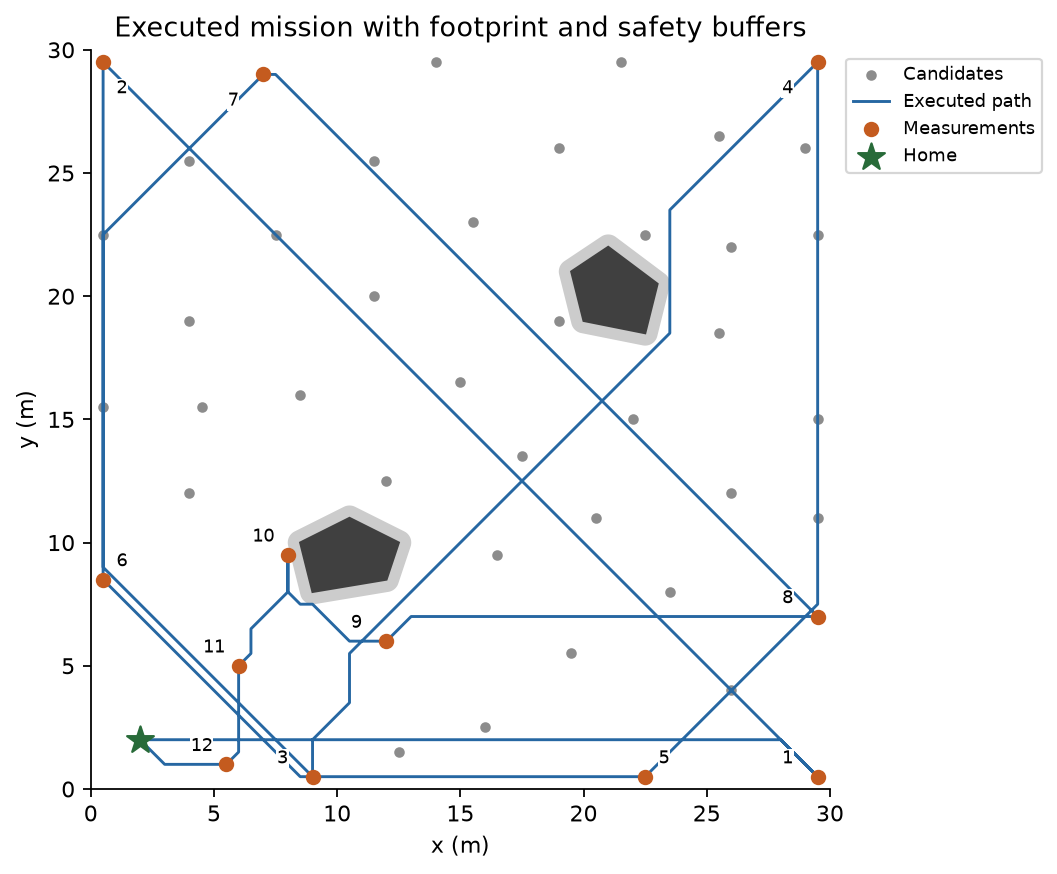

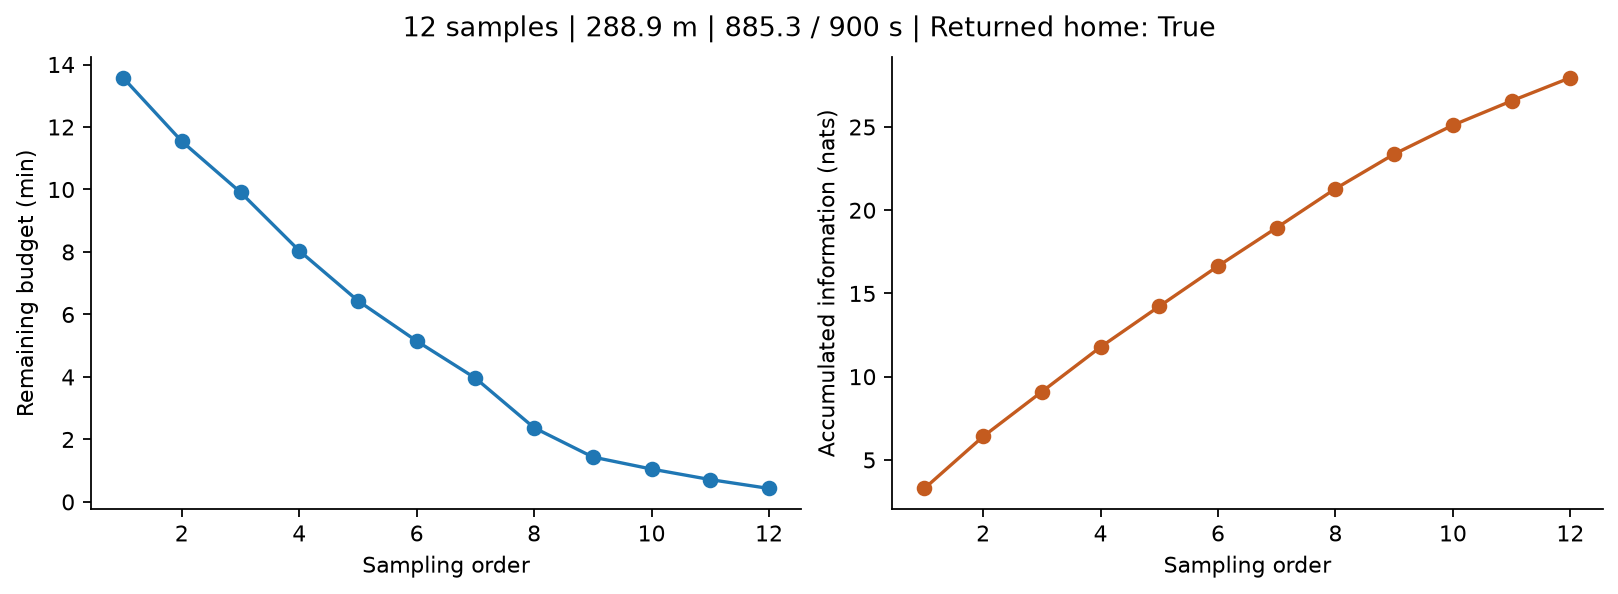

In [4]:
table(["Metric", "Result"], [
    ["Successful measurements / GP updates", summary["measurements"]],
    ["GRG calls", summary["planning_calls"]],
    ["Travel distance (m)", summary["travel_distance_m"]],
    ["Travel time (s)", summary["travel_time_s"]],
    ["Total mission time (s)", summary["elapsed_s"]],
    ["Remaining budget at home (s)", summary["budget_s"] - summary["elapsed_s"]],
    ["Returned home", summary["returned_home"]],
    ["Information gain (nats)", summary["information_gain_nats"]],
])
log = [r for r in read_csv(main / "planning_log.csv") if r["gp_updated"] == "True"]
table(["Sample", "Node", "Arrival (s)", "GP timestamp (h)", "Temperature (°C)"], [
    [i + 1, r["next_node"], float(r["arrival_s"]), float(r["arrival_t_h"]), float(r["temperature_c"])]
    for i, r in enumerate(log)
])
figure("01_navigation.png")
figure("06_progress.png")

Conclusion: the default mission completed 12 measurements and 13 planning calls.
The last call found no feasible extra sample. The robot returned without collision
at 885.30 s. All 14 saved mission checks passed. See the full
[planning log](10.18_result/baseline/main/planning_log.csv) and
[verification](10.18_result/baseline/main/verification.json).


## 3. Fixed-target reconstruction

Objective: reconstruct the same 1,393 accessible points at 12.25 h before and after sampling.
The evaluation grid is independent of the candidate set. Coverage uses latent intervals
`mean ± 1.96 × latent standard deviation`. Sensor noise is not added to these intervals.

Source: [GP updates](testing_code/baseline/gp.py), [evaluation](testing_code/baseline/evaluate.py),
[figures](testing_code/baseline/plots.py).


State | RMSE (°C) | MAE (°C) | Mean variance (°C²) | 95% coverage | Mean interval width (°C)
--- | --- | --- | --- | --- | ---
Initial | 0.0537052 | 0.0375374 | 0.00737109 | 1 | 0.27393
Final | 0.0237278 | 0.0184093 | 0.000950452 | 1 | 0.114235

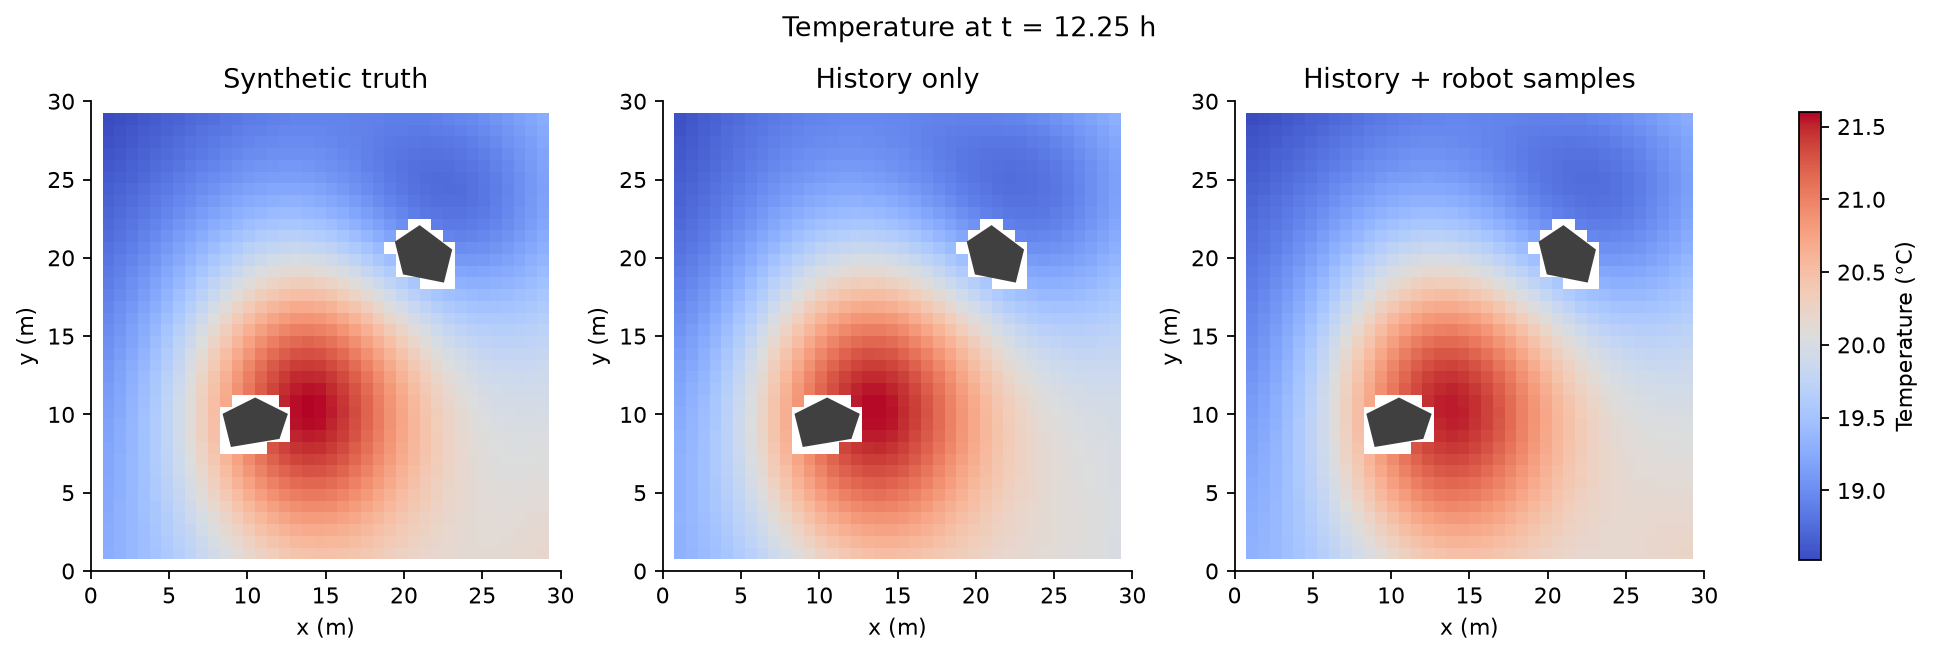

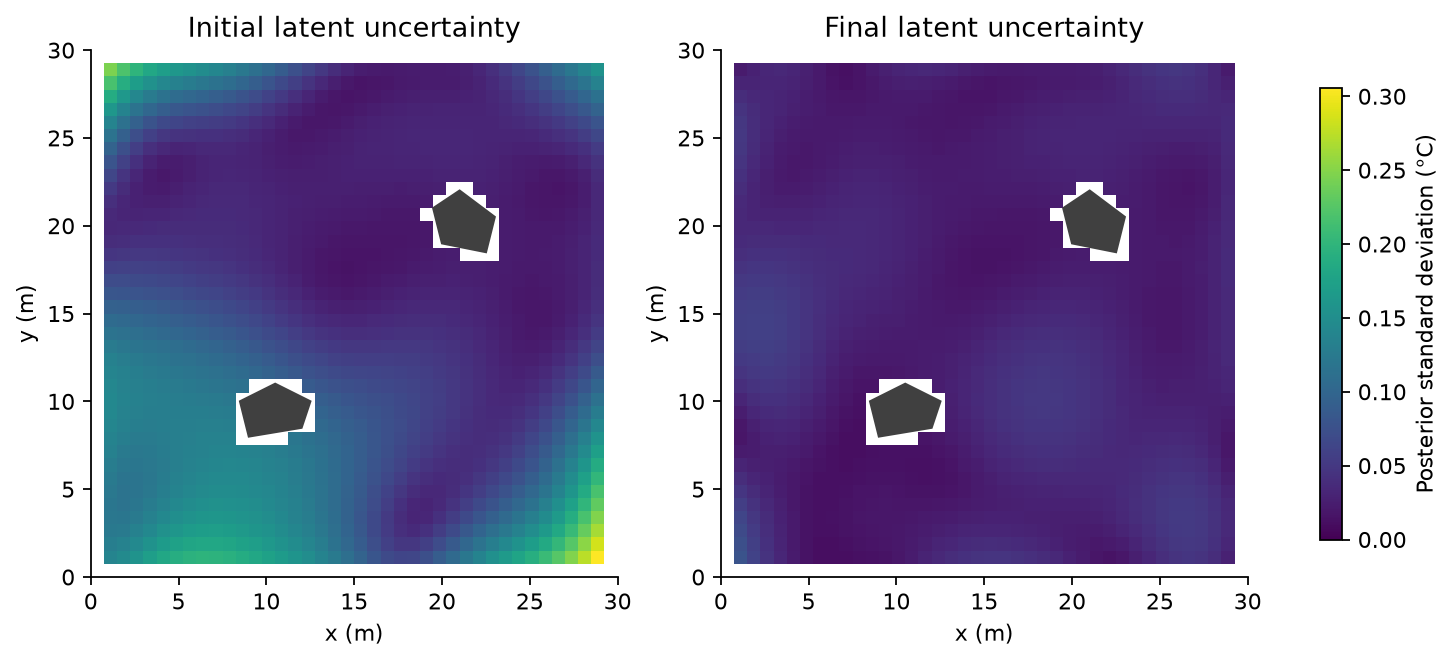

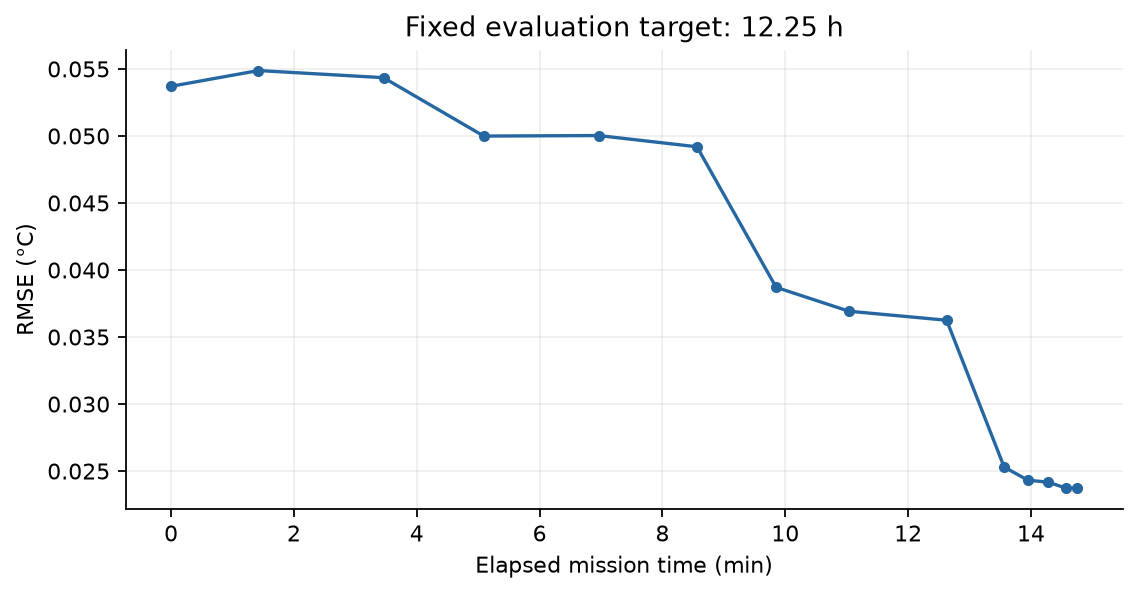

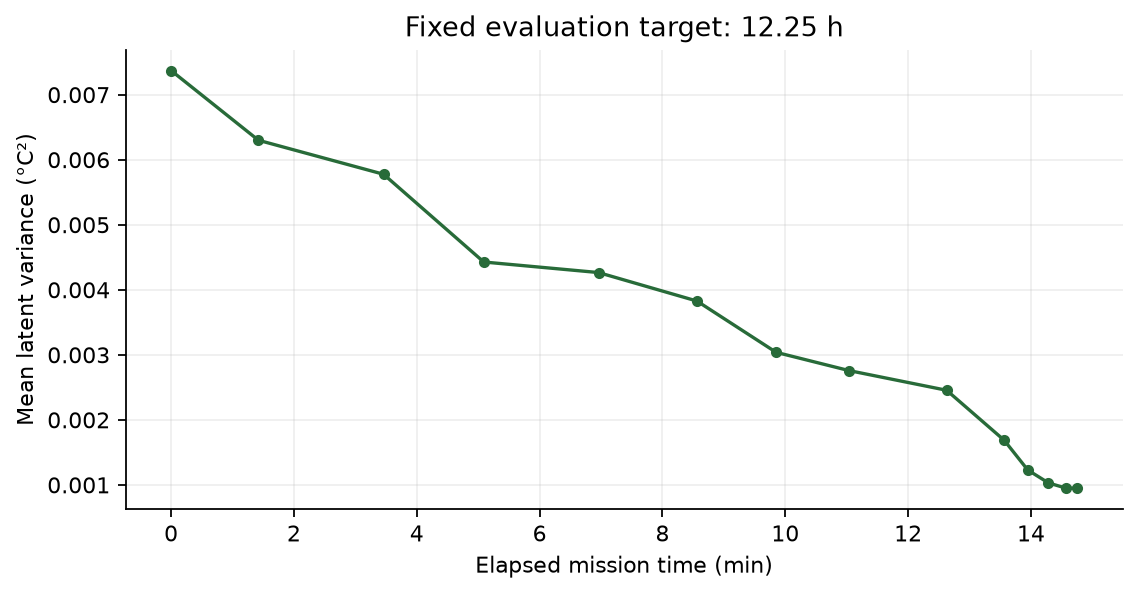

In [5]:
saved = np.load(main / "reconstruction.npz")
query, truth = saved["query"], saved["truth"]
# Replay both saved models and verify the reported fields.
for model, index in [(initial_gp, 0), (final_gp, -1)]:
    prediction = model.predict(query)
    np.testing.assert_allclose(prediction["mean"], saved["means"][index], atol=1e-10, rtol=0)
    np.testing.assert_allclose(prediction["latent_var"], saved["variances"][index], atol=1e-10, rtol=0)
rows = []
for label, index in [("Initial", 0), ("Final", -1)]:
    error = saved["means"][index] - truth
    variance = saved["variances"][index]
    rows.append([label, np.sqrt(np.mean(error**2)), np.mean(np.abs(error)),
                 variance.mean(), np.mean(np.abs(error) <= 1.959963984540054 * np.sqrt(variance)),
                 np.mean(2 * 1.959963984540054 * np.sqrt(variance))])
table(["State", "RMSE (°C)", "MAE (°C)", "Mean variance (°C²)", "95% coverage", "Mean interval width (°C)"], rows)
assert np.max(np.diff(saved["variances"], axis=0)) <= 1e-9
for name in ["02_temperature.png", "03_uncertainty.png", "04_rmse.png", "05_variance.png"]:
    figure(name)

Conclusion: RMSE changed from 0.05371°C to 0.02373°C
(55.8% reduction).
Mean latent variance changed from 0.007371 to 0.000950°C²
(87.1% reduction). RMSE rose slightly after the first sample;
it need not decrease after every update. Variance did not increase at any fixed query.
Both initial and final coverage were 100%. This indicates conservative intervals on
this noise-free field, not calibrated 95% coverage on real measurements.


## 4. Reproducibility and runtime

Objective: repeat seed 18 and check two additional seeds without changing the method.
Report runtime separately from simulated mission time. GRG query time is included in GRG time.


In [6]:
runs = read_csv(result / "seed_summary.csv")
table(["Run", "Samples", "Initial RMSE (°C)", "Final RMSE (°C)", "Elapsed (s)", "Home"], [
    [r["run"], r["measurements"], float(r["initial_rmse_c"]), float(r["final_rmse_c"]),
     float(r["elapsed_s"]), r["returned_home"]] for r in runs
])
repeat = read_json(result / "verification" / "reproducibility.json")
assert repeat["passed"]
print(f"Fixed-seed reproduction: {sum(repeat['checks'].values())}/{len(repeat['checks'])} checks passed.")
table(["Main-run runtime", "Seconds"], [
    ["Map and travel precomputation", summary["map_and_travel_precompute_s"]],
    ["GP training", summary["gp_training_s"]],
    ["GRG total", summary["grg_runtime_s"]],
    ["GRG posterior queries (subset)", summary["grg_covariance_query_s"]],
    ["Full run including plots and file output", summary["total_wall_s"]],
])

Run | Samples | Initial RMSE (°C) | Final RMSE (°C) | Elapsed (s) | Home
--- | --- | --- | --- | --- | ---
main | 12 | 0.0537052 | 0.0237278 | 885.304 | True
repeat | 12 | 0.0537052 | 0.0237278 | 885.304 | True
seed_19 | 15 | 0.0415276 | 0.0147426 | 894.471 | True
seed_20 | 13 | 0.0914692 | 0.0386966 | 899.103 | True

Fixed-seed reproduction: 14/14 checks passed.


Main-run runtime | Seconds
--- | ---
Map and travel precomputation | 0.936141
GP training | 0.35621
GRG total | 0.661687
GRG posterior queries (subset) | 0.301734
Full run including plots and file output | 3.03991

## 5. Overall conclusion

The implementation and correctness objectives were achieved under the stated simulation assumptions.

| Step | Objective | Outcome and evidence |
|---|---|---|
| 1. Environment | Provide a valid map and feasible sampling destinations. | Achieved. Two valid obstacles, footprint inflation, reachable candidates, and collision-free navigation passed verification. |
| 2. Historical initialization | Build the initial 3D GP without future data. | Achieved. Train on 100 observations from 0–12 h only. The initial posterior conditions on all historical data. |
| 3. Posterior queries | Supply correct mean and joint covariance to the system. | Achieved. Numerical tests agree with analytical conditioning and GPyTorch. GRG receives posterior covariance, not raw prior covariance. |
| 4. Time-aware GRG | Score ordered routes using arrival times and budget constraints. | Achieved. Controlled tests show that sampling time and route order change information gain. Planned routes include sampling and return costs. |
| 5. Navigation and sensing | Execute paths and measure at actual arrival poses and times. | Achieved. 12 valid samples were collected without collision. Failure tests reject unsuccessful navigation and invalid sensor data. |
| 6. Online feedback | Update after each sample and replan with the updated posterior. | Achieved. 12 posterior updates and 13 planning calls completed. All 112 observations remain included; parameters and normalization remain fixed. |
| 7. Mission completion | Collect at least three samples and return within 900 s. | Achieved. The robot returned at 885.30 s after travelling 288.86 m. It stopped sampling when no feasible extra sample remained. |
| 8. Reconstruction | Evaluate initial and final estimates at the same target field. | Achieved. RMSE changed from 0.05371 to 0.02373°C over 1,393 points at 12.25 h. Mean variance changed from 0.007371 to 0.000950°C². |
| 9. Verification | Check component correctness, reproducibility, and backend contracts. | Achieved. All 22 automated tests and 14 main-mission checks passed. The repeat matched all 14 reproduction checks. Seeds 19 and 20 also completed feasible missions and reduced final RMSE. Navigation and temperature contracts are defined and tested with Python backends. |

Online sampling improved final reconstruction in all three distinct seeds. Fixed-query variance did not increase during updates. Main-run 95% coverage was 100% before and after sampling, indicating conservative intervals on this field. Real-data uncertainty calibration, planner superiority, and ROS 2/Nav2 operation remain unvalidated by this experiment.

## 6. Next step?

The Python GP–GRG–navigation–measurement loop is operational under the tested assumptions.
The mission is short relative to the learned 7.41 h temporal lengthscale. Controlled tests
establish time dependence; the default mission alone does not establish a temporal-planning benefit.
Fixed-kernel covariance planning responds to sampling locations and times. Temperature values
update the mean but do not directly change the route reward.

The simulator omits turning, acceleration, localization error, and compute delay in mission time.
GRG maximizes sampled-point information, not target-grid RMSE. Next, implement real sensor and
Nav2 adapters and validate timing and return reserves. Planner comparisons remain separate.


## 7. Benchmark: GRG recursive depth

**Objective.** Test whether depths 3 and 5 improve realized sampling information and fixed-target reconstruction enough to justify their planning cost. Depth 2 is the frozen baseline. Only recursive depth changes.

**Procedure.** Reproduce seed 18 at depth 2. Screen an initial call at depths 2, 3, and 5. Run independent missions for screened-feasible depths across seeds 18–22. Each seed shares one initial GP checkpoint, history, candidate set, map, and target grid. The Sampling-Point MI reward remains unchanged. Per-call and worker wall limits are 90 s and 900 s; simulated mission time is unchanged.

Depth gives an upper bound of `2**depth - 1` sampling visits: 3, 7, and 31. Budget constraints may reduce this count. Runtime and feasibility are measured, not inferred from the bound.

[Code](testing_code/grg_depth_benchmark/run_benchmark.py) · [Technical report](10.18_result/grg_depth_benchmark/report.md) · [All runs](10.18_result/grg_depth_benchmark/runs.csv)

In [1]:
from pathlib import Path
import csv
import json
import numpy as np
from IPython.display import Markdown, Image, display

root = Path.cwd()
bench = root / "10.18_result" / "grg_depth_benchmark"
def load_csv(name):
    with (bench / name).open(newline="") as file:
        return list(csv.DictReader(file))
def show_table(columns, rows):
    def fmt(value):
        return f"{value:.6g}" if isinstance(value, (float, np.floating)) else str(value)
    lines = [" | ".join(columns), " | ".join(["---"] * len(columns))]
    lines += [" | ".join(fmt(value) for value in row) for row in rows]
    display(Markdown("\n".join(lines)))
reproduction = json.loads((bench / "verification/baseline_reproduction.json").read_text())
assert reproduction["passed"]
screening = load_csv("screening.csv")
show_table(["Depth", "Status", "Planning time (s)", "Planned samples", "Planned MI (nats)"], [
    [r["depth"], r["status"], float(r["runtime_s"]) if r.get("runtime_s") else
     ("≥ " + format(float(r.get("timed_out_call_s") or 90), ".3f")),
     r.get("sampling_waypoints") or "—", float(r["gain"]) if r.get("gain") else "—"] for r in screening
])
print("Depth 2 reproduced all baseline checks. Timeout completion times are unknown.")

Depth | Status | Planning time (s) | Planned samples | Planned MI (nats)
--- | --- | --- | --- | ---
2 | SUCCESS | 0.0805441 | 3 | 9.09786
3 | SUCCESS | 20.8474 | 7 | 18.9803
5 | TIMEOUT | ≥ 90.069 | — | —

Depth 2 reproduced all baseline checks. Timeout completion times are unknown.


### Mission results

Realized MI is computed from the final executed samples conditioned on the shared initial GP. Revised route rewards are not summed. Missing final metrics represent uncompleted or unattempted missions, not zero performance.

In [2]:
runs = load_csv("runs.csv")
def num(row, key):
    return float(row[key]) if row.get(key) else "—"
show_table(["Seed", "Depth", "Status", "Initial RMSE (°C)", "Final RMSE (°C)",
            "Realized MI (nats)", "Samples", "Elapsed (s)", "Home"], [
    [r["seed"], r["depth"], r["status"], num(r, "initial_rmse_c"), num(r, "final_rmse_c"),
     num(r, "realized_information_gain_nats"), r.get("measurements") or "—",
     num(r, "elapsed_s"), r.get("returned_home") or "—"] for r in runs
])
stats = load_csv("aggregate.csv")
show_table(["Depth", "Completed", "Failed", "Mission timeouts", "Not run after screening"], [
    [r["depth"], r["successful_runs"], r["failed_runs"], r["mission_timeouts"],
     r["not_run_after_screening"]] for r in stats
])
def mean_sd(row, key):
    if not row.get(key + "_mean"):
        return "N/A"
    mean, sd = float(row[key + "_mean"]), row.get(key + "_sd")
    return f"{mean:.6g} ± {float(sd):.3g}" if sd else f"{mean:.6g}"
show_table(["Depth", "Completed", "Final RMSE (°C)", "Final variance (°C²)",
            "Realized MI (nats)", "Mean planning (s)", "Max planning (s)"], [
    [r["depth"], r["successful_runs"], mean_sd(r, "final_rmse_c"), mean_sd(r, "final_variance_c2"),
     mean_sd(r, "realized_information_gain_nats"), mean_sd(r, "mean_planning_s"),
     mean_sd(r, "max_planning_s")] for r in stats
])
pairs = load_csv("paired_summary.csv")
show_table(["Depth − 2", "Pairs", "RMSE difference (°C)", "Variance difference (°C²)",
            "MI difference (nats)", "Mean planning ratio"], [
    [r["depth"], r["complete_pairs"], mean_sd(r, "final_rmse_c_difference"),
     mean_sd(r, "final_variance_c2_difference"), mean_sd(r, "realized_information_gain_nats_difference"),
     mean_sd(r, "mean_planning_ratio")] for r in pairs
])

Seed | Depth | Status | Initial RMSE (°C) | Final RMSE (°C) | Realized MI (nats) | Samples | Elapsed (s) | Home
--- | --- | --- | --- | --- | --- | --- | --- | ---
18 | 2 | SUCCESS | 0.0537052 | 0.0237278 | 27.9601 | 12 | 885.304 | True
18 | 3 | SUCCESS | 0.0537052 | 0.0188706 | 34.3975 | 18 | 897.933 | True
18 | 5 | NOT_RUN_SCREEN_TIMEOUT | — | — | — | — | — | —
19 | 2 | SUCCESS | 0.0415276 | 0.0147426 | 26.2622 | 15 | 894.471 | True
19 | 3 | SUCCESS | 0.0415276 | 0.0218584 | 32.4349 | 19 | 897.244 | True
19 | 5 | NOT_RUN_SCREEN_TIMEOUT | — | — | — | — | — | —
20 | 2 | SUCCESS | 0.0914692 | 0.0386966 | 31.0076 | 13 | 899.103 | True
20 | 3 | SUCCESS | 0.0914692 | 0.0215887 | 39.7525 | 19 | 893 | True
20 | 5 | NOT_RUN_SCREEN_TIMEOUT | — | — | — | — | — | —
21 | 2 | SUCCESS | 0.071279 | 0.025203 | 28.5587 | 14 | 899.751 | True
21 | 3 | SUCCESS | 0.071279 | 0.0206282 | 34.1628 | 19 | 899.814 | True
21 | 5 | NOT_RUN_SCREEN_TIMEOUT | — | — | — | — | — | —
22 | 2 | SUCCESS | 0.0856545 | 0.0275688 | 28.7374 | 13 | 895.875 | True
22 | 3 | SUCCESS | 0.0856545 | 0.0263297 | 35.4787 | 19 | 898.308 | True
22 | 5 | NOT_RUN_SCREEN_TIMEOUT | — | — | — | — | — | —

Depth | Completed | Failed | Mission timeouts | Not run after screening
--- | --- | --- | --- | ---
2 | 5 | 0 | 0 | 0
3 | 5 | 0 | 0 | 0
5 | 0 | 0 | 0 | 5

Depth | Completed | Final RMSE (°C) | Final variance (°C²) | Realized MI (nats) | Mean planning (s) | Max planning (s)
--- | --- | --- | --- | --- | --- | ---
2 | 5 | 0.0259878 ± 0.00861 | 0.00132257 ± 0.000535 | 28.5052 ± 1.71 | 0.0516795 ± 0.0019 | 0.0852051 ± 0.00351
3 | 5 | 0.0218551 ± 0.00276 | 0.000797148 ± 0.000264 | 35.2453 ± 2.75 | 7.77459 ± 0.375 | 21.8431 ± 0.395
5 | 0 | N/A | N/A | N/A | N/A | N/A

Depth − 2 | Pairs | RMSE difference (°C) | Variance difference (°C²) | MI difference (nats) | Mean planning ratio
--- | --- | --- | --- | --- | ---
3 | 5 | -0.00413263 ± 0.00872 | -0.000525425 ± 0.000278 | 6.74009 ± 1.2 | 150.423 ± 4.02
5 | 0 | N/A | N/A | N/A | N/A

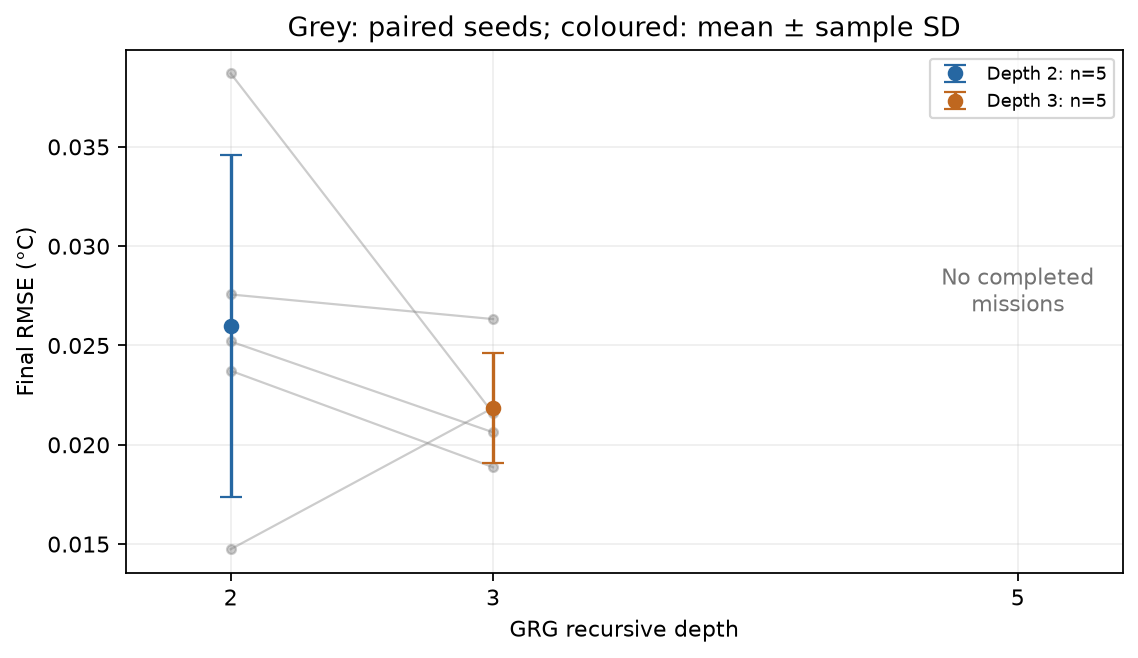

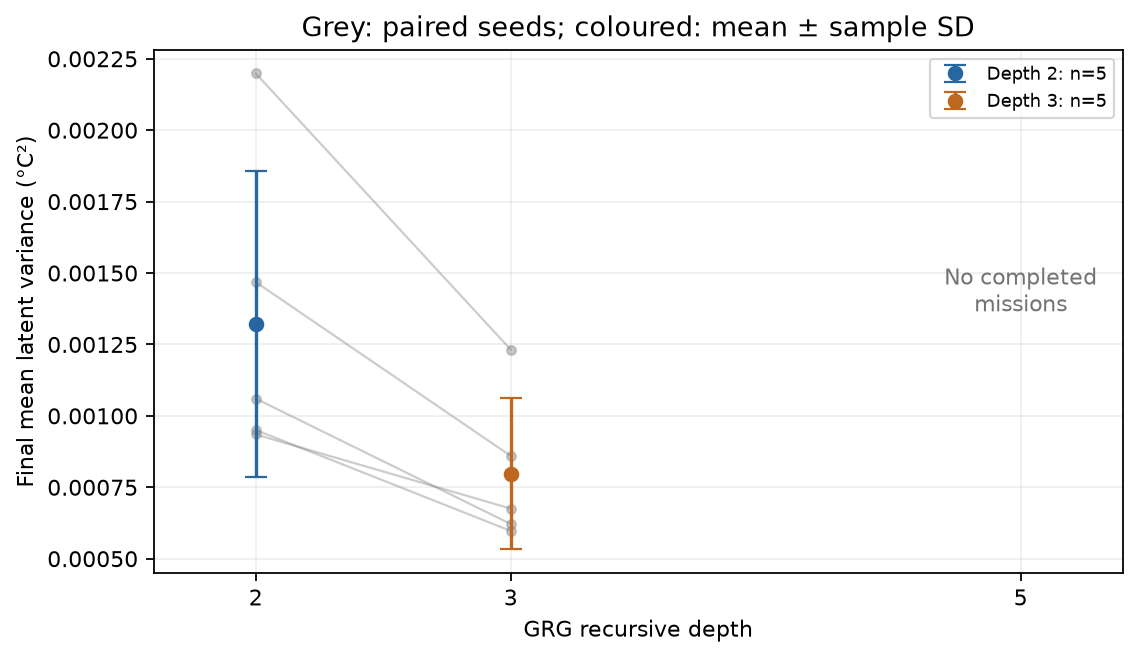

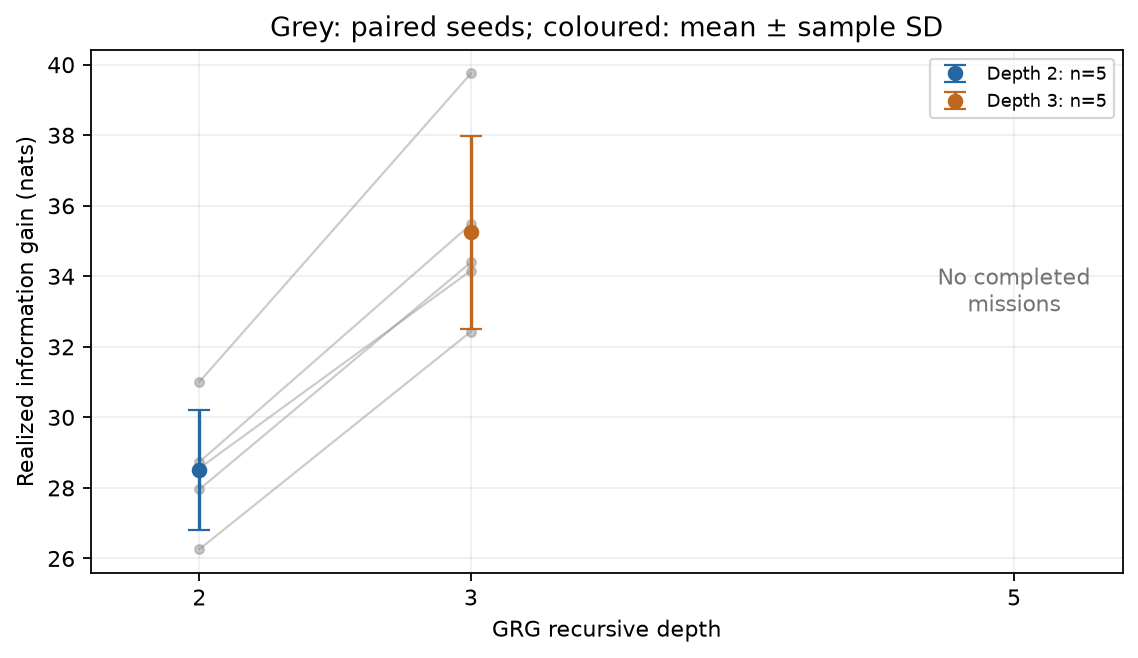

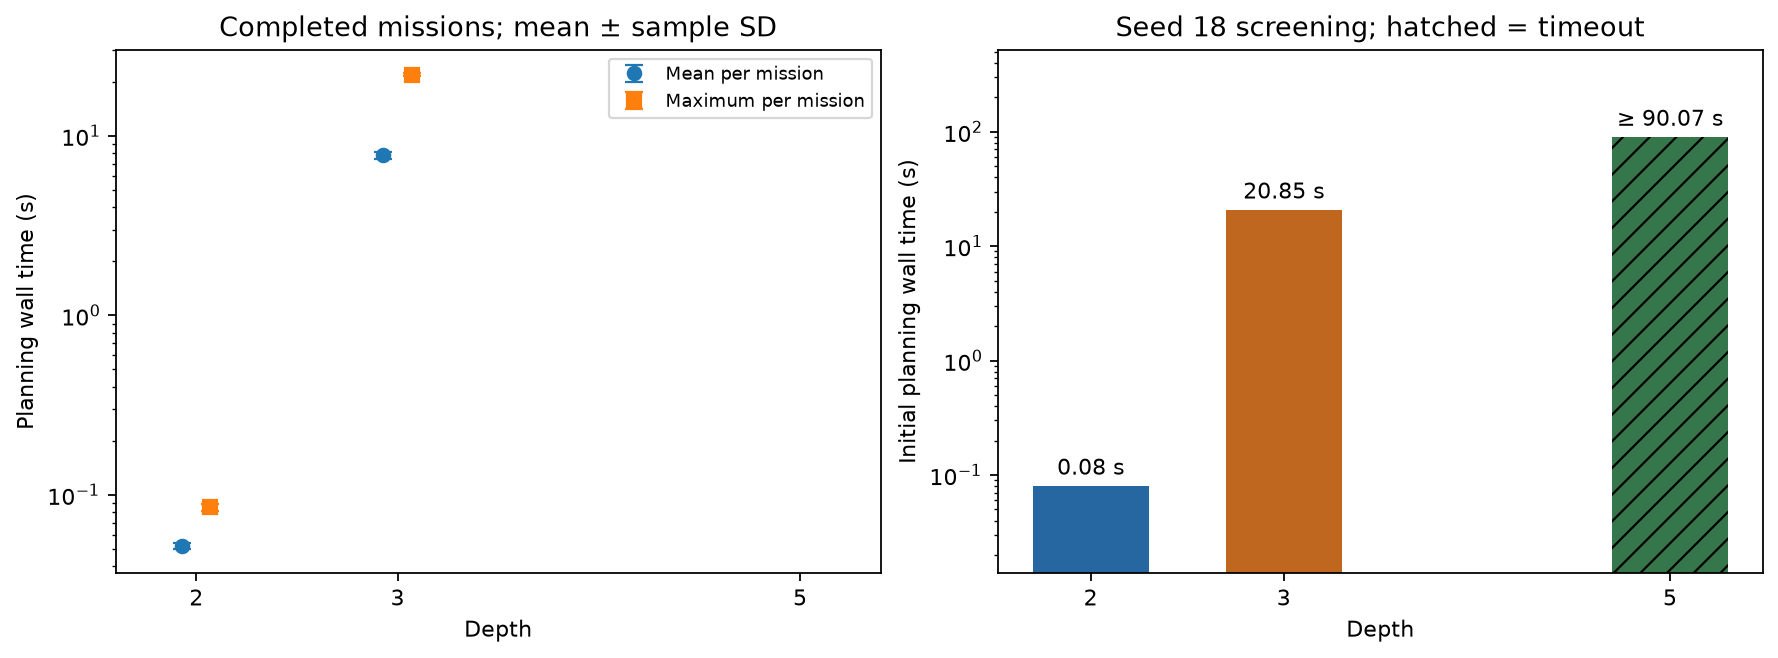

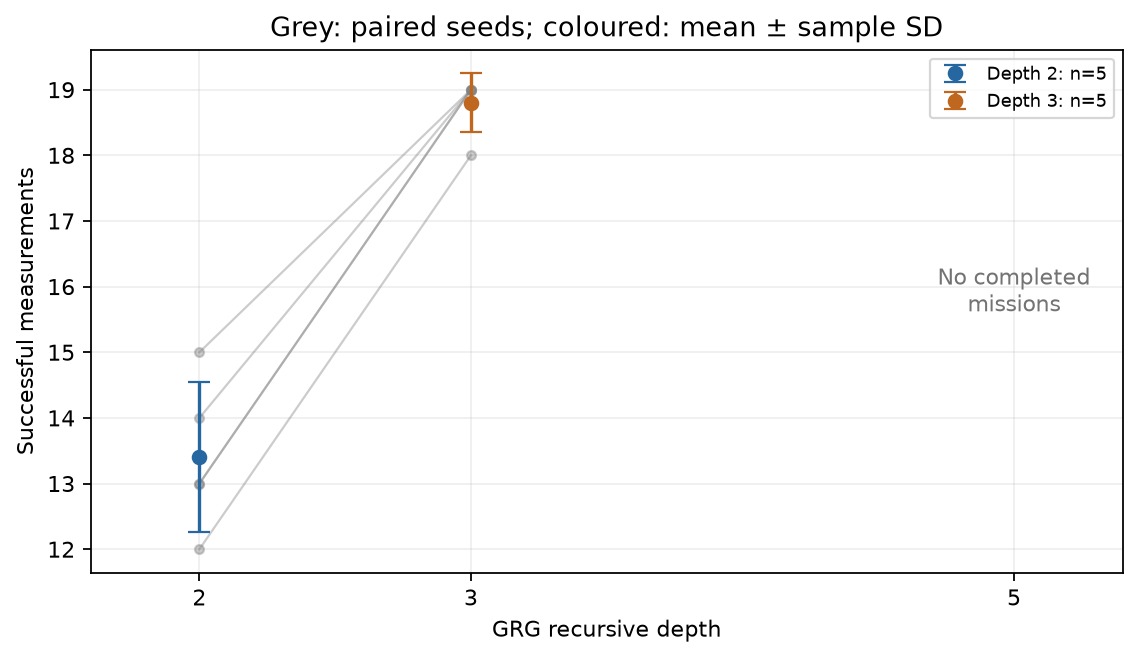

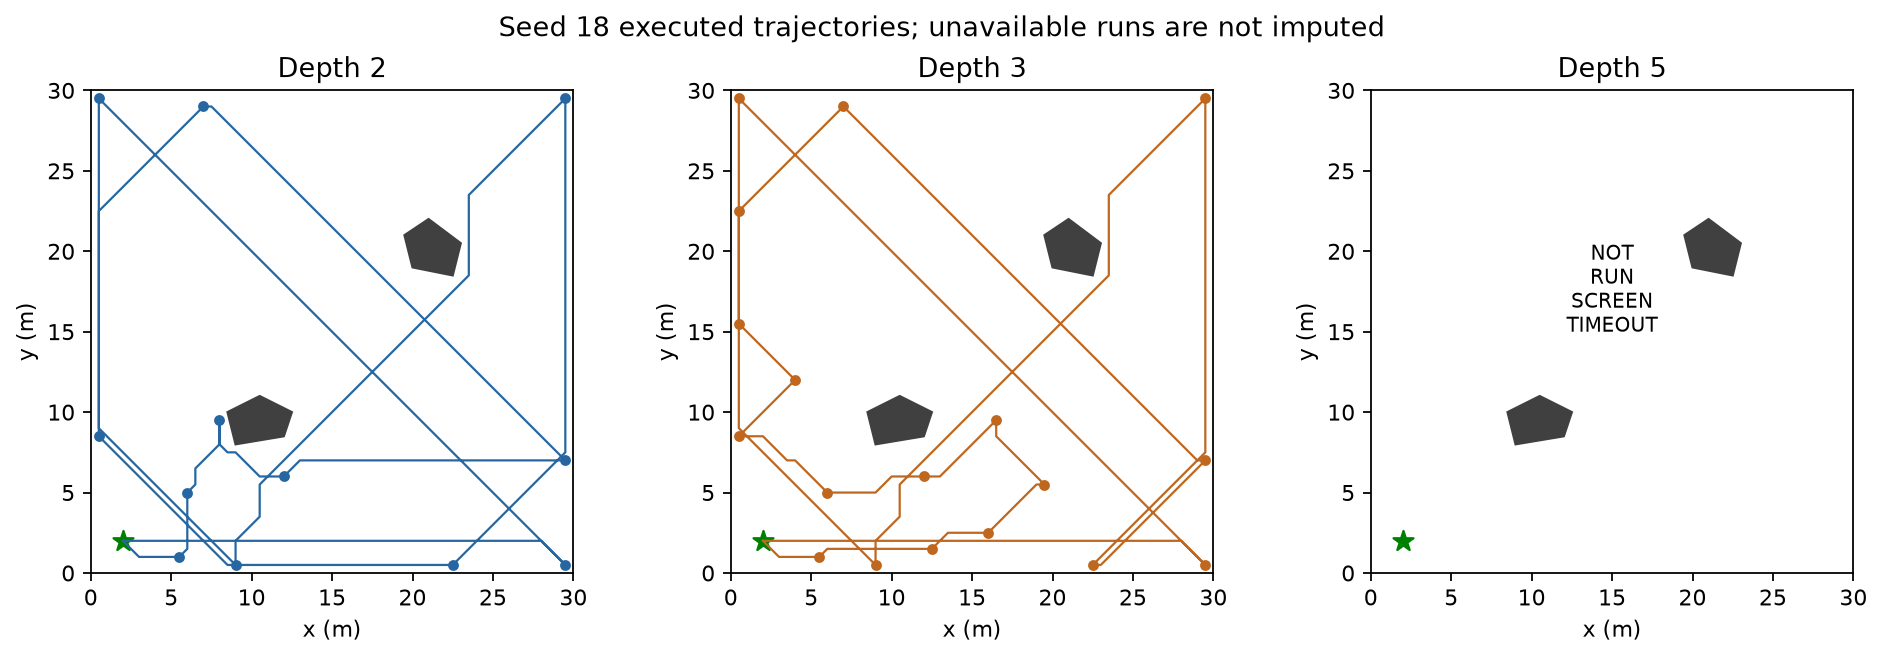

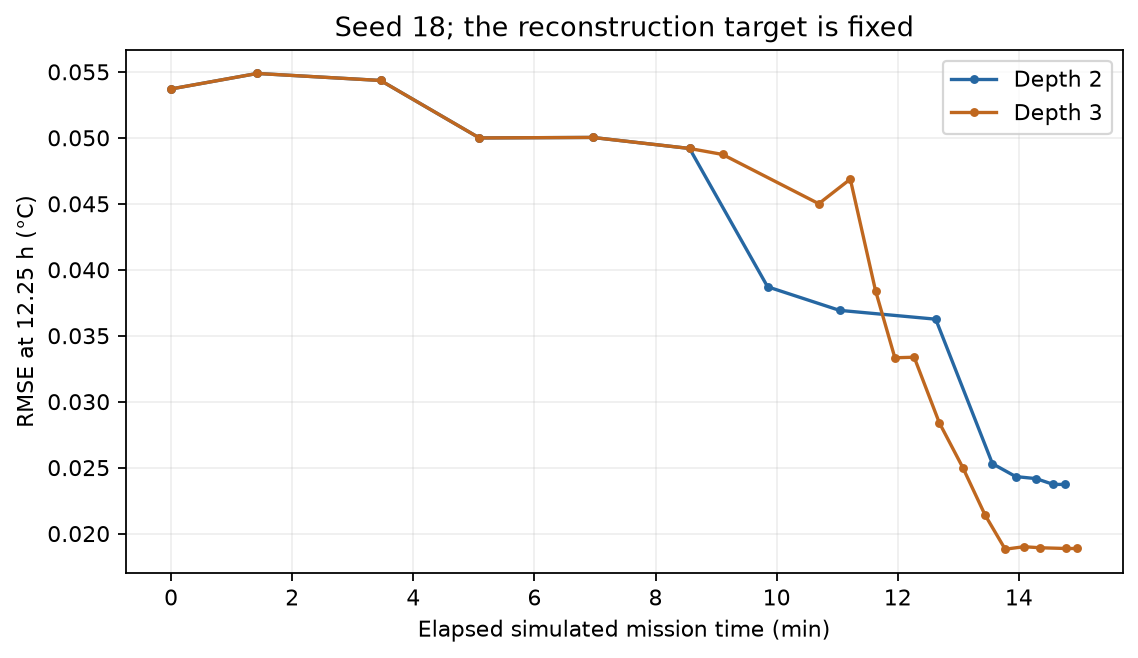

In [3]:
for name in ["01_rmse_depth.png", "02_variance_depth.png", "03_information_depth.png",
             "04_planning_runtime.png", "05_measurements_depth.png",
             "06_trajectories.png", "07_rmse_time.png"]:
    display(Image(filename=str(bench / "figures" / name)))

### Conclusions and verification

The following conclusions use completed paired missions only. Five seeds do not establish statistical significance. The detailed report records timeouts and all ten research questions.

In [4]:
report = (bench / "report.md").read_text()
conclusion = report.split("## Paired results and answers", 1)[1].split("## Limits", 1)[0]
display(Markdown(conclusion.strip()))
for name in ["regression/tests.json", "benchmark_tests.json", "baseline_sources_unchanged.json"]:
    check = json.loads((bench / "verification" / name).read_text())
    assert check["passed"], name
    print(name, "passed", check.get("count", ""))

- Depth 3 versus depth 2 (5 pairs): mean final RMSE difference -0.004133°C; mean final variance difference -0.000525°C²; mean realized MI difference +6.7401 nats. Mean planning latency ratio: 150.4×; total planning ratio: 207.5×. Executed sample sequences changed in 5/5 pairs. Final RMSE improved in 4/5 pairs and worsened in 1/5 pairs.
- Depth 5: no complete paired missions. Reconstruction, realized MI, route changes, and mission runtime cannot be compared from the screening result alone.
- Depth(s) [5] exceeded or failed initial screening. Full missions were not attempted at those depths. They were not silently reduced or counted as successful runs.
- Additional lookahead does not guarantee better realized information or RMSE under receding-horizon execution.
- Depth 2 completes the validated mission with low latency. Retain it as the provisional ROS/Nav2 default unless the paired gains justify a larger planning delay. This is an engineering recommendation for this configuration, not proof of optimality.

regression/tests.json passed 22
benchmark_tests.json passed 6
baseline_sources_unchanged.json passed 
